# Which events break stock co-movement, and do the breaks last?

**DSAI4102 Applied Data Mining · Event notebook** (builds on `final_project.ipynb`)
Farid Abdul Rehman · Muzayyan Parkar · Mohamad Zain

`final_project.ipynb` mines co-movement rules and finds *when* the structure changes. This notebook asks
*what happened then*, using an event calendar, and whether the changes are temporary or permanent.

| Hypothesis | Section | Test |
|---|---|---|
| **H1** Breaks and shock days line up with events more often than chance | 3, 6 | event-date shift test (the whole calendar moved by a random number of days, 1,000 times) |
| **H1a** A company's earnings move its own group (earnings spillover) | 5 | association rules mined on earnings days, compared with ordinary big-move days |
| **H1b** Rate and inflation news hits rate-sensitive stocks, not the whole list | 4 | share of stocks making a major move on event days vs other days |
| **H1c** At least half of the top-1% unusual days match a known event | 3 | labelled table + shift test |
| **H1d** AI product launches don't break the structure; AI business news does | 3, 6, 7 | the five AI events in every test |
| **H2** Most breaks are temporary; events that change a business cause lasting change | 7 | recovery curves against a "normal drift" baseline |

**Inputs.** `data/prices.csv` (same file as the final notebook), `data/events.csv` from `python build_events.py`,
and optionally `data/earnings_dates.csv` from `python build_events.py --earnings` (needs internet access to
Yahoo Finance). Without the earnings file, Section 5 is skipped and everything else runs.

**Outputs.** Every table and figure goes to `outputs/events/`; every quoted number goes to
`outputs/events/key_numbers_events.json`.

### Results at a glance (run of 21 Nov 2026, data to 13 Nov 2026, **without** the earnings file)

| Question | Answer |
|---|---|
| Do unusual days match known events? (H1c) | **Partly.** 41% of the 27 most unusual days fall on a rate decision, CPI or jobs report, or within a day of a listed shock, against 14% for shifted calendars (p = 0.001). That is below the 50% we wrote down, and almost all of it comes from the hand-picked shocks (37% vs 2%). Scheduled releases alone match 11%, no better than chance (13%). Of the 16 unmatched days, 7 fall in the Feb–Mar 2020 crash (only two of its dates are listed), several look like earnings reactions (META +9.4 and MSFT +7.6 on 2025-07-31; JNJ, TSLA and NFLX on 2023-07-20; ADSK −19.5 on 2017-11-29), and 2020-11-04 is the day after the 2020 election, which the shock list leaves out. Adding events after looking at this table would inflate the match rate, so the earnings file is the fair next test. |
| Are scheduled event days more unusual? (H1) | **Rate decisions yes; CPI and jobs reports no.** FOMC days sit at the 62nd anomaly percentile on median (p = 0.002, significant after Benjamini–Hochberg). CPI and jobs-report days are no different from quiet days. |
| Who reacts to rate and jobs news? (H1b) | **The bank, not the groups.** After removing the market, JPM makes a major move 1.52× as often on FOMC days (95% interval 1.14–1.95) and 1.38× on jobs-report days (1.04–1.70). Group averages stay near 1; AI enablers are borderline on FOMC days (1.18, 1.00–1.37). CPI moves nobody. |
| Event rules (events as items) | Two rules pass the thresholds, `FOMC_DAY -> AMD_UP` (lift 1.92) and `FOMC_DAY -> AMAT_UP` (1.78), against 0.05 expected on shifted calendars, but neither survives Benjamini–Hochberg over all 9,720 possible right-hand sides. |
| Do shocks line up with structure breaks? (H1) | **No.** Shocks sit at the 55th percentile of the local break score on average, against 50% for shifted dates (p = 0.26; p = 0.05 with z = 1.5). The 2016 election is the only big break with a listed shock nearby. The mid-2025 and late-2025 breaks have no listed shock; the nearest unusual days look like earnings reactions. |
| AI launches vs AI business news (H1d) | **Supported on unusual days.** ChatGPT (68th percentile) and GPT-4 (49th) were ordinary days; Nvidia's guidance (99.3rd), DeepSeek (99.6th) and Oracle's backlog (97.0th) were not. Only DeepSeek is followed by a lasting change in the whole structure. |
| Are breaks temporary? (H2) | **Mostly there is no break to recover from.** Of the 15 shocks with enough data, 12 show no structure break across all pairs and 3 show a lasting change (2016 election, 2019 yuan devaluation, DeepSeek); none is temporary. Within pairs that include an AI stock, 4 are temporary (Feb 2018 volatility spike, 2018 tariffs, both COVID dates), 1 lasting, 10 no break. These counts change with the settings (Section 8), so treat H2 as suggestive. Half-year windows cannot see a break that lasts only weeks. |

## 1. Settings

The first block repeats the final notebook's settings unchanged, so the items, rules and anomaly scores here are
the same as there. The second block holds the settings that are new to this notebook.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from mlxtend.frequent_patterns import fpgrowth
from scipy.stats import hypergeom, mannwhitneyu
from sklearn.ensemble import IsolationForest

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- same as final_project.ipynb ------------------------------------------------
DATA_PATH = Path("data/prices.csv")
GROUPS = {
    "AI enablers": ["NVDA", "AMD", "AVGO", "TSM", "MU", "QCOM", "INTC", "AMAT", "LRCX", "ASML"],
    "Big Tech": ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "ORCL", "NFLX", "TSLA"],
    "Traditional software": ["ADBE", "CRM", "IBM", "CSCO", "CHGG", "INTU", "SAP", "ACN", "NOW", "WDAY", "ADSK", "CTSH"],
    "Non-tech baseline": ["JPM", "XOM", "JNJ", "PG", "KO", "WMT", "UNH", "CAT", "HD", "PFE"],
}
MARKET = "SPY"
STUDY_START = "2016-01-01"
BETA_WINDOW = 252
VOL_WINDOW = 60
Z_K = 1.0
SEED = 42

# ---- new in this notebook ---------------------------------------------------------
EVENTS_PATH = Path("data/events.csv")
EARNINGS_PATH = Path("data/earnings_dates.csv")
OUT_DIR = Path("outputs/events")
OUT_DIR.mkdir(parents=True, exist_ok=True)

TOP_SHARE = 0.01          # "unusual day" = top 1% of Isolation Forest scores (as in the final notebook)
SHOCK_TOLERANCE = 1       # a one-off shock matches an unusual day within +-1 trading day
N_SHIFTS = 1000           # random calendar shifts for the event-date test
MIN_SHIFT = 21            # a shift moves the calendar by at least one month
SPAN = 126                # half-year windows before and after a date for structure comparisons
GRID_STEP = 5             # local break score every 5 trading days (weekly)
PEAK_GAP = 63             # break peaks must be at least a quarter apart
NEAR = 21                 # events within +-21 trading days of a break peak are listed as "nearby"
H2_OFFSETS = list(range(0, 505, 21))   # recovery curve: post-event windows start 0..504 trading days after the event
EVENT_TYPES = ["FOMC", "CPI", "NFP", "SHOCK"]
COND_MIN_SUPPORT = 0.25   # event rules: consequent on at least 25% of the event days ...
COND_MIN_COUNT = 5        # ... and on at least 5 event days
COND_MIN_LIFT = 1.5
FDR_Q = 0.05
rng = np.random.default_rng(SEED)

TICKERS = [t for members in GROUPS.values() for t in members]
GROUP_OF = {t: g for g, members in GROUPS.items() for t in members}
SHORT = {"AI enablers": "AI", "Big Tech": "BigTech", "Traditional software": "Software", "Non-tech baseline": "Baseline"}
KEY = {}

Plot style and helpers (same colours as the final notebook).

In [2]:
INK, INK_SOFT, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
GROUP_COLORS = dict(zip(GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#898781"]))
TYPE_COLORS = {"FOMC": "#7a4fc9", "CPI": "#eb6834", "NFP": "#1baf7a", "SHOCK": "#b3261e", "EARN": "#2a78d6"}
HIGHLIGHT = "#b3261e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 9, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_SOFT, "axes.titlecolor": INK,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 1.8,
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
})


def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png")


def year_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def short_label(name, width=24):
    # Cut a long event name at a word boundary for figure labels.
    name = name.split(" (")[0].split(";")[0]
    if len(name) <= width:
        return name
    return name[:width].rsplit(" ", 1)[0] + "..."


def benjamini_hochberg(p_values, q=FDR_Q, n_tests=None):
    # True for every p-value that survives the Benjamini-Hochberg procedure (same function as the final notebook).
    p = np.asarray(p_values, dtype=float)
    m = len(p) if n_tests is None else n_tests
    order = np.argsort(p)
    passed = p[order] <= q * np.arange(1, len(p) + 1) / m
    keep = np.zeros(len(p), dtype=bool)
    if passed.any():
        keep[order[:np.max(np.nonzero(passed)[0]) + 1]] = True
    return keep

## 2. Data, items, unusual days and the event calendar

Items are built exactly as in the final notebook: residual return (stock return minus beta × SPY return, beta
from the previous 252 days), then a major move is at least 1 × the stock's own typical move over the previous
60 days. The function also builds the other settings used in the robustness section (Section 8).

In [3]:
def market_model_residuals(returns, market, window):
    betas = pd.DataFrame({t: returns[t].rolling(window).cov(market) / market.rolling(window).var()
                          for t in returns.columns}).shift(1)
    return returns - betas.mul(market, axis=0), betas


def find_major_moves(returns, z_k, vol_window):
    typical_move = returns.rolling(vol_window).std().shift(1)
    score = returns / typical_move
    up, down = score >= z_k, score <= -z_k
    up.columns = [f"{t}_UP" for t in returns.columns]
    down.columns = [f"{t}_DOWN" for t in returns.columns]
    return pd.concat([up, down], axis=1), score


prices = pd.read_csv(DATA_PATH, index_col=0, parse_dates=True).sort_index()[TICKERS + [MARKET]]
all_returns = prices.pct_change()
stock_returns, market_returns = all_returns[TICKERS], all_returns[MARKET]
residual_returns, _ = market_model_residuals(stock_returns, market_returns, BETA_WINDOW)
RETURNS = {"residual": residual_returns, "raw": stock_returns}


def build_items(mode="residual", z_k=Z_K):
    items, z = find_major_moves(RETURNS[mode], z_k, VOL_WINDOW)
    return items.loc[STUDY_START:], z.loc[STUDY_START:]


def anomaly_scores(z):
    # Isolation Forest on the 40 daily z-scores, same settings as the final notebook (Section 8 there).
    Z = z.clip(-10, 10).fillna(0)
    forest = IsolationForest(n_estimators=300, contamination=0.01, random_state=SEED).fit(Z)
    return pd.Series(-forest.score_samples(Z), index=Z.index, name="anomaly")


items, zscores = build_items()
DAYS = items.index
N_DAYS = len(DAYS)
anomaly = anomaly_scores(zscores)
basket_size = items.sum(axis=1)
print(f"{N_DAYS} baskets from {DAYS[0].date()} to {DAYS[-1].date()}")

# Check: the top unusual days must match the final notebook's saved table.
saved_top = Path("outputs/final/top_anomalous_days.csv")
if saved_top.exists():
    theirs = pd.read_csv(saved_top, parse_dates=["Date"])["Date"].head(12)
    ours = anomaly.nlargest(12).index
    print(f"Top-12 unusual days identical to final_project.ipynb: {list(ours) == list(theirs)}")

2733 baskets from 2016-01-04 to 2026-11-13
Top-12 unusual days identical to final_project.ipynb: True


**Event calendar.** Every event is placed on the first trading day the market could react to it (a Sunday
announcement moves to Monday). Earnings are optional: a report after the close moves to the next trading day.

In [4]:
def to_trading_day(dates):
    # First trading day on or after each date; NaT when the date is outside the study period.
    pos = DAYS.searchsorted(pd.DatetimeIndex(dates))
    return pd.DatetimeIndex([DAYS[p] if p < N_DAYS else pd.NaT for p in pos])


events = pd.read_csv(EVENTS_PATH, parse_dates=["announced"])
events["day"] = to_trading_day(events["announced"])
events = events[events["day"].notna() & (events["announced"] >= DAYS[0])].reset_index(drop=True)
POS = {d: i for i, d in enumerate(DAYS)}
events["pos"] = events["day"].map(POS)

# One True/False column per event type, indexed by trading day.
event_days = pd.DataFrame(False, index=DAYS, columns=EVENT_TYPES)
for t in EVENT_TYPES:
    event_days.loc[events.loc[events["event_type"] == t, "day"], t] = True
event_days["MACRO"] = event_days[["FOMC", "CPI", "NFP"]].any(axis=1)

# Earnings (optional).
HAS_EARNINGS = EARNINGS_PATH.exists()
if HAS_EARNINGS:
    earn = pd.read_csv(EARNINGS_PATH, parse_dates=["timestamp"])
    earn = earn[earn["ticker"].isin(TICKERS)].copy()
    after_close = earn["timestamp"].dt.hour >= 16
    earn["announced"] = earn["timestamp"].dt.normalize() + pd.to_timedelta(after_close.astype(int), unit="D")
    earn["day"] = to_trading_day(earn["announced"])
    earn = earn[earn["day"].notna() & (earn["timestamp"] >= DAYS[0])].drop_duplicates(["ticker", "day"])
    earn_matrix = pd.DataFrame(False, index=DAYS, columns=TICKERS)
    for t, d in zip(earn["ticker"], earn["day"]):
        earn_matrix.loc[d, t] = True
    event_days["EARN_COUNT"] = earn_matrix.sum(axis=1)
    print(f"Earnings: {len(earn)} reaction days for {earn['ticker'].nunique()} tickers")
else:
    earn, earn_matrix = None, None
    print("No data/earnings_dates.csv: earnings parts are skipped. Run `python build_events.py --earnings` to add them.")

summary = events.groupby("event_type").agg(events=("day", "size"), first=("day", "min"), last=("day", "max"))
summary["share of trading days"] = [event_days[t].mean() for t in summary.index]
KEY["calendar"] = {t: int(n) for t, n in summary["events"].items()} | {"earnings_file": HAS_EARNINGS}
summary

No data/earnings_dates.csv: earnings parts are skipped. Run `python build_events.py --earnings` to add them.


,events,first,last,share of trading days
event_type,,,,
CPI,130,2016-01-20,2026-11-10,0.047567
FOMC,88,2016-01-27,2026-10-28,0.032199
NFP,130,2016-01-08,2026-11-06,0.047567
SHOCK,19,2016-06-24,2025-09-10,0.006952


## 3. Unusual days: how many match a known event? (H1c, H1)

The 1% most unusual days (Isolation Forest on residual z-scores, as in the final notebook) are labelled with
every event on that day; a one-off shock counts within ±1 trading day because news often breaks the day before.

**Is the match rate more than chance?** Rate decisions and data releases happen on about one day in eight, so
some unusual days will fall on them by luck. The **event-date shift test** moves the *whole calendar* forward by
a random number of trading days (at least a month, wrapping around at the end) and counts the matches again,
1,000 times. Shifting the whole calendar keeps its rhythm (monthly releases, eight Fed meetings a year) and only
breaks the link between events and market days.

In [5]:
def shifted(mask, k):
    # Move a True/False day series forward by k trading days, wrapping around at the end.
    return np.roll(np.asarray(mask), k)


def widen(mask, tol):
    # True within +-tol trading days of any True day.
    m = np.asarray(mask, dtype=bool)
    out = m.copy()
    for k in range(1, tol + 1):
        out[k:] |= m[:-k]
        out[:-k] |= m[k:]
    return out


def match_share(top_pos, masks):
    hit = np.zeros(len(top_pos), dtype=bool)
    for m in masks:
        hit |= m[top_pos]
    return hit.mean()


def shift_test(top_pos, masks, n=N_SHIFTS):
    # Observed share of top days that match any of the masks, and the same share for random calendar shifts.
    observed = match_share(top_pos, masks)
    shifts = rng.integers(MIN_SHIFT, N_DAYS - MIN_SHIFT, size=n)
    null = np.array([match_share(top_pos, [shifted(m, k) for m in masks]) for k in shifts])
    return observed, null, float((null >= observed).mean())


def label_days(days):
    rows = []
    for d in days:
        p = POS[d]
        near = events[(events["event_type"] == "SHOCK") & ((events["pos"] - p).abs() <= SHOCK_TOLERANCE)]
        same = events[(events["event_type"] != "SHOCK") & (events["pos"] == p)]
        labels = list(same["event_type"]) + list(near["name"])
        if HAS_EARNINGS:
            reporters = list(earn_matrix.columns[earn_matrix.loc[d]])
            if reporters:
                labels.append("earnings: " + ", ".join(reporters))
        movers = zscores.loc[d].abs().sort_values(ascending=False).head(5).index
        rows.append({"date": d.date(), "anomaly": round(anomaly.loc[d], 3), "moves in basket": int(basket_size.loc[d]),
                     "events": "; ".join(labels) if labels else "(none in calendar)",
                     "largest residual moves (z)": ", ".join(f"{t} {zscores.loc[d, t]:+.1f}" for t in movers)})
    return pd.DataFrame(rows)


n_top = int(round(TOP_SHARE * N_DAYS))
top_days = anomaly.nlargest(n_top).index
top_pos = np.array([POS[d] for d in top_days])
shock_mask = widen(event_days["SHOCK"], SHOCK_TOLERANCE)
macro_mask = event_days["MACRO"].to_numpy()

obs_any, null_any, p_any = shift_test(top_pos, [macro_mask, shock_mask])
obs_macro, null_macro, p_macro = shift_test(top_pos, [macro_mask])
obs_shock, null_shock, p_shock = shift_test(top_pos, [shock_mask])

labelled = label_days(top_days)
labelled.to_csv(OUT_DIR / "top_unusual_days_labelled.csv", index=False)
KEY["h1c"] = {"n_top_days": n_top,
              "share_matched_macro_or_shock": round(obs_any, 3), "null_mean": round(null_any.mean(), 3), "p": p_any,
              "share_matched_macro": round(obs_macro, 3), "null_mean_macro": round(null_macro.mean(), 3), "p_macro": p_macro,
              "share_matched_shock": round(obs_shock, 3), "null_mean_shock": round(null_shock.mean(), 3), "p_shock": p_shock}
print(json.dumps(KEY["h1c"], indent=1))
labelled

{
 "n_top_days": 27,
 "share_matched_macro_or_shock": 0.407,
 "null_mean": 0.139,
 "p": 0.001,
 "share_matched_macro": 0.111,
 "null_mean_macro": 0.125,
 "p_macro": 0.695,
 "share_matched_shock": 0.37,
 "null_mean_shock": 0.019,
 "p_shock": 0.0
}


,date,anomaly,moves in basket,events,largest residual moves (z)
0,2017-06-09,0.599,29,(none in calendar),"PFE +6.7, CRM -6.0, AMAT -5.5, META -5.1, AAPL..."
1,2016-11-10,0.595,33,US election result (Trump),"GOOGL -5.6, JPM +5.5, KO -5.5, IBM +4.8, PG -4.0"
2,2020-03-18,0.584,33,(none in calendar),"ASML -8.3, CSCO +7.0, AVGO -5.8, LRCX -4.4, CH..."
3,2017-11-29,0.580,31,(none in calendar),"ADSK -19.5, LRCX -5.9, AMAT -5.3, ASML -5.3, W..."
4,2016-11-09,0.575,34,US election result (Trump),"PFE +10.0, CAT +6.9, JPM +4.5, CHGG +4.1, TSM ..."
5,2020-11-09,0.564,23,Pfizer vaccine efficacy result,"PG -7.4, JPM +6.8, HD -6.7, PFE +5.8, XOM +5.6"
6,2020-03-13,0.563,28,COVID crash day after the Fed's Sunday emergen...,"ORCL +9.8, ADBE +9.0, JPM +6.4, INTC +6.0, XOM..."
7,2024-11-06,0.558,24,US election result (Trump),"JPM +8.2, HD -5.6, SAP -5.2, CAT +4.6, CTSH +4.0"
8,2020-03-23,0.557,29,(none in calendar),"HD +5.9, NFLX +5.4, AMAT +5.4, ADBE +5.4, SAP ..."
9,2020-03-19,0.551,32,(none in calendar),"AVGO +7.9, WDAY +5.9, KO -5.9, ACN +5.3, JNJ -4.9"


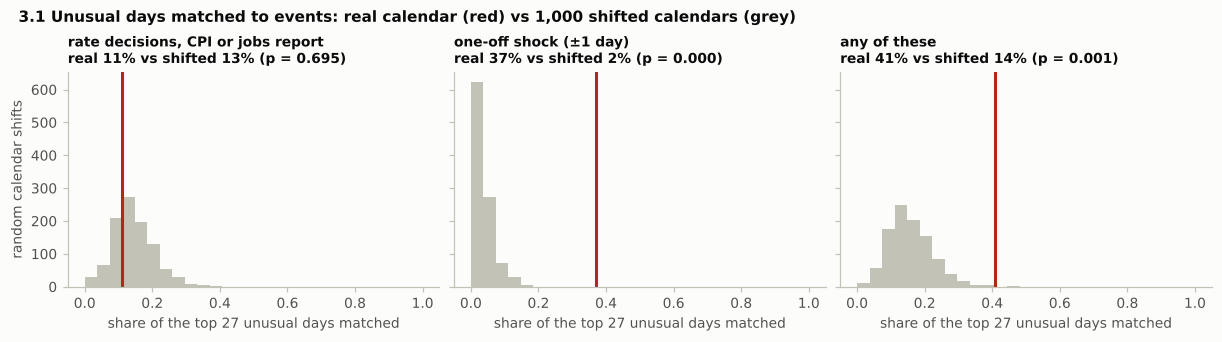

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout="constrained", sharey=True)
for ax, (title, obs, null, p) in zip(axes, [("rate decisions, CPI or jobs report", obs_macro, null_macro, p_macro),
                                            ("one-off shock (±1 day)", obs_shock, null_shock, p_shock),
                                            ("any of these", obs_any, null_any, p_any)]):
    ax.hist(null, bins=np.arange(0, 1.0001, 1 / n_top), color=AXIS)
    ax.axvline(obs, color=HIGHLIGHT, lw=2)
    ax.set_title(f"{title}\nreal {obs:.0%} vs shifted {null.mean():.0%} (p = {p:.3f})", fontsize=9)
    ax.set_xlabel(f"share of the top {n_top} unusual days matched")
axes[0].set_ylabel("random calendar shifts")
fig.suptitle("3.1 Unusual days matched to events: real calendar (red) vs 1,000 shifted calendars (grey)",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "3_1_unusual_days_shift_test")
plt.show()

**The AI events (H1d).** Where each AI event's day ranks among all days (1.00 = the most unusual day).

In [7]:
ai_rows = events[events["category"].isin(["ai_launch", "ai_business"])]
ai_table = pd.DataFrame({
    "event": ai_rows["name"].values,
    "kind": ai_rows["category"].values,
    "anomaly percentile": [round(float((anomaly <= anomaly.loc[d]).mean()), 3) for d in ai_rows["day"]],
    "moves in basket": [int(basket_size.loc[d]) for d in ai_rows["day"]],
}, index=ai_rows["day"].dt.date)
KEY["h1d_anomaly_percentile"] = ai_table.set_index("event")["anomaly percentile"].to_dict()
ai_table

,event,kind,anomaly percentile,moves in basket
day,,,,
2022-11-30,ChatGPT released,ai_launch,0.684,13
2023-03-14,GPT-4 announced,ai_launch,0.485,10
2023-05-25,Nvidia's AI revenue guidance,ai_business,0.993,24
2025-01-27,DeepSeek sell-off,ai_business,0.996,29
2025-09-10,Oracle's $455bn cloud backlog,ai_business,0.970,18


## 4. Are scheduled event days more unusual, and for whom? (H1, H1b)

**4.1 Unusual-ness by event type.** Anomaly scores on each type's days against days with no rate decision, data
release or shock (Mann–Whitney test, one-sided: "event days are more unusual"). Benjamini–Hochberg across the
four types.

In [8]:
quiet = ~(event_days[["FOMC", "CPI", "NFP"]].any(axis=1).to_numpy() | widen(event_days["SHOCK"], 1))
anomaly_pct = anomaly.rank(pct=True)
rows = []
for t in EVENT_TYPES:
    on = event_days[t].to_numpy()
    p = mannwhitneyu(anomaly[on], anomaly[quiet], alternative="greater").pvalue
    rows.append({"type": t, "days": int(on.sum()), "median anomaly percentile": anomaly_pct[on].median(),
                 "share in top 5%": float((anomaly_pct[on] >= 0.95).mean()),
                 "median moves in basket": basket_size[on].median(), "p (vs quiet days)": p})
rows.append({"type": "quiet days", "days": int(quiet.sum()), "median anomaly percentile": anomaly_pct[quiet].median(),
             "share in top 5%": float((anomaly_pct[quiet] >= 0.95).mean()),
             "median moves in basket": basket_size[quiet].median(), "p (vs quiet days)": np.nan})
by_type = pd.DataFrame(rows).set_index("type")
by_type["significant (BH 5%)"] = False
by_type.loc[EVENT_TYPES, "significant (BH 5%)"] = benjamini_hochberg(by_type.loc[EVENT_TYPES, "p (vs quiet days)"])
by_type.to_csv(OUT_DIR / "unusualness_by_event_type.csv")
KEY["h1_by_type"] = by_type.round(4).to_dict(orient="index")
by_type.round(3)

,days,median anomaly percentile,share in top 5%,median moves in basket,p (vs quiet days),significant (BH 5%)
type,,,,,,
FOMC,88,0.620,0.023,10.0,0.002,True
CPI,130,0.472,0.031,9.0,0.800,False
NFP,130,0.457,0.046,8.0,0.830,False
SHOCK,19,0.977,0.632,22.0,0.000,True
quiet days,2348,0.494,0.046,9.0,NaN,False


**4.2 Who moves on rate and data days? (H1b)** For each group: the share of its stocks that make a major move
on event days, divided by the same share on quiet days. 1.0 = no different from a quiet day. Intervals: 95%
bootstrap over event days. Because the market has been removed, a ratio above 1 means the group reacts *more
than its usual market sensitivity explains*.

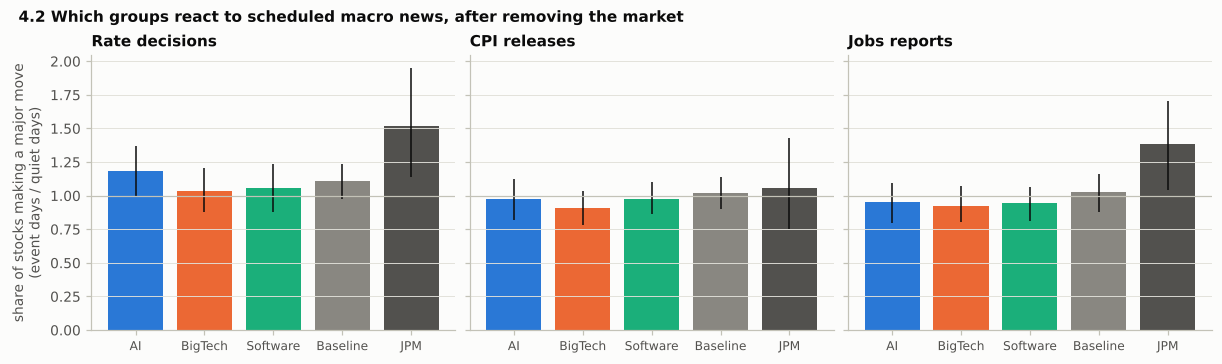

,event,group,ratio,low,high
0,FOMC,AI enablers,1.18,1.00,1.37
1,FOMC,Big Tech,1.04,0.88,1.21
2,FOMC,Traditional software,1.06,0.88,1.24
3,FOMC,Non-tech baseline,1.11,0.98,1.23
4,FOMC,JPM (the one bank),1.52,1.14,1.95
5,CPI,AI enablers,0.98,0.82,1.12
6,CPI,Big Tech,0.91,0.78,1.03
7,CPI,Traditional software,0.98,0.86,1.10
8,CPI,Non-tech baseline,1.02,0.90,1.14
9,CPI,JPM (the one bank),1.06,0.75,1.43


In [9]:
move_any = pd.DataFrame({t: items[f"{t}_UP"] | items[f"{t}_DOWN"] for t in TICKERS})


def move_ratio(cols, on, n_boot=500):
    rate = move_any[cols].to_numpy().mean(axis=1)
    base = rate[quiet].mean()
    ev = rate[on]
    boot = np.array([rng.choice(ev, len(ev)).mean() for _ in range(n_boot)]) / base
    return ev.mean() / base, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


ratio_rows = []
for t in ["FOMC", "CPI", "NFP"]:
    on = event_days[t].to_numpy()
    for g, members in GROUPS.items():
        r, lo, hi = move_ratio(members, on)
        ratio_rows.append({"event": t, "group": g, "ratio": r, "low": lo, "high": hi})
    r, lo, hi = move_ratio(["JPM"], on)
    ratio_rows.append({"event": t, "group": "JPM (the one bank)", "ratio": r, "low": lo, "high": hi})
ratios = pd.DataFrame(ratio_rows)
ratios.to_csv(OUT_DIR / "move_ratio_by_group.csv", index=False)
KEY["h1b_move_ratio"] = {f"{r.event} {r.group}": [round(r.ratio, 2), round(r.low, 2), round(r.high, 2)] for r in ratios.itertuples()}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), layout="constrained", sharey=True)
order = list(GROUPS) + ["JPM (the one bank)"]
colors = list(GROUP_COLORS.values()) + [INK_SOFT]
for ax, t in zip(axes, ["FOMC", "CPI", "NFP"]):
    sub = ratios[ratios["event"] == t].set_index("group").loc[order]
    x = np.arange(len(order))
    ax.bar(x, sub["ratio"], color=colors)
    ax.vlines(x, sub["low"], sub["high"], color=INK, lw=1)
    ax.axhline(1, color=AXIS, lw=0.8)
    ax.set_xticks(x, [SHORT.get(g, "JPM") for g in order], fontsize=8)
    ax.set_title({"FOMC": "Rate decisions", "CPI": "CPI releases", "NFP": "Jobs reports"}[t])
    ax.grid(axis="y")
axes[0].set_ylabel("share of stocks making a major move\n(event days / quiet days)")
fig.suptitle("4.2 Which groups react to scheduled macro news, after removing the market", x=0.01, ha="left",
             fontweight="bold", fontsize=10)
save(fig, "4_2_move_ratio_by_group")
plt.show()
ratios.round(2)

**Which single stocks react most on rate-decision days?** Top 8 by move ratio (each stock's own rate).

In [10]:
fomc_on = event_days["FOMC"].to_numpy()
stock_ratio = (move_any[fomc_on].mean() / move_any[quiet].mean()).sort_values(ascending=False)
KEY["h1b_top_fomc_stocks"] = stock_ratio.head(8).round(2).to_dict()
stock_ratio.head(8).round(2).to_frame("FOMC move ratio").assign(group=lambda d: [GROUP_OF[t] for t in d.index])

,FOMC move ratio,group
AMD,1.56,AI enablers
JPM,1.52,Non-tech baseline
ORCL,1.49,Big Tech
ADBE,1.46,Traditional software
AVGO,1.39,AI enablers
AMAT,1.36,AI enablers
INTC,1.34,AI enablers
MSFT,1.32,Big Tech


## 5. Events as items: association rules mined on event days (H1a)

**How.** An event becomes an item (`FOMC_DAY`, `EARN_NVDA`, ...). Rules with an event on the left are mined
from the **conditional database**: only the baskets of days that contain the left-hand side, which is how
FP-Growth itself grows itemsets. For a left-hand side A and a right-hand side X:

* confidence = share of A's days on which X happened;
* lift = confidence / share of *all* days on which X happened;
* a one-sided Fisher exact test asks whether X happens on A's days more than chance, and Benjamini–Hochberg
  counts every right-hand side that could have been tested (every single item and every pair).

**Chance check.** The same mining on event days moved by random calendar shifts. Rules found there are what
chance alone produces.

In [11]:
ALL_ITEMS = list(items.columns)
N_POSSIBLE_RHS = len(ALL_ITEMS) + len(ALL_ITEMS) * (len(ALL_ITEMS) - 1) // 2


def mine_given(mask, name, basket=items, exclude=()):
    # Rules "name -> X" from the baskets of the days in `mask`. X has 1 or 2 items and excludes `exclude`.
    mask = np.asarray(mask, dtype=bool)
    n_a = int(mask.sum())
    if n_a < COND_MIN_COUNT:
        return pd.DataFrame()
    cols = [c for c in basket.columns if c not in set(exclude)]
    cond = basket.loc[mask, cols]
    min_sup = max(COND_MIN_SUPPORT, COND_MIN_COUNT / n_a)
    sets = fpgrowth(cond, min_support=min_sup, use_colnames=True, max_len=2)
    if sets.empty:
        return pd.DataFrame()
    full = basket[cols].to_numpy(dtype=bool)
    col_of = {c: i for i, c in enumerate(cols)}
    out = []
    for sup_cond, s in zip(sets["support"], sets["itemsets"]):
        idx = [col_of[c] for c in s]
        n_x = int(full[:, idx].all(axis=1).sum())
        n_ax = int(round(sup_cond * n_a))
        lift = sup_cond / (n_x / len(basket))
        if lift < COND_MIN_LIFT:
            continue
        out.append({"rule": f"{name} -> {', '.join(sorted(s))}", "lhs": name, "rhs": ", ".join(sorted(s)),
                    "lhs days": n_a, "joint days": n_ax, "confidence": sup_cond, "lift": lift,
                    "p": hypergeom.sf(n_ax - 1, len(basket), n_a, n_x)})
    return pd.DataFrame(out)


def mine_event_items(day_masks, n_tests_per_lhs=N_POSSIBLE_RHS):
    # day_masks: {lhs name: (mask, items to exclude from the right-hand side)}
    rules = pd.concat([mine_given(m, n, exclude=ex) for n, (m, ex) in day_masks.items()], ignore_index=True)
    if rules.empty:
        return rules
    rules["significant"] = benjamini_hochberg(rules["p"], n_tests=n_tests_per_lhs * len(day_masks))
    return rules.sort_values("lift", ascending=False).reset_index(drop=True)


macro_lhs = {f"{t}_DAY": (event_days[t].to_numpy(), ()) for t in ["FOMC", "CPI", "NFP"]}
macro_rules = mine_event_items(macro_lhs)
n_shift_checks = 20
chance_counts = []
for k in rng.integers(MIN_SHIFT, N_DAYS - MIN_SHIFT, size=n_shift_checks):
    r = mine_event_items({n: (shifted(m, k), ex) for n, (m, ex) in macro_lhs.items()})
    chance_counts.append(len(r))
KEY["macro_rules"] = {"rules": len(macro_rules),
                      "significant": int(macro_rules["significant"].sum()) if len(macro_rules) else 0,
                      "rules_on_shifted_calendars_mean": float(np.mean(chance_counts))}
print(json.dumps(KEY["macro_rules"], indent=1))
macro_rules.to_csv(OUT_DIR / "event_rules_macro.csv", index=False)
macro_rules.head(15).round(3)

{
 "rules": 2,
 "significant": 0,
 "rules_on_shifted_calendars_mean": 0.05
}


,rule,lhs,rhs,lhs days,joint days,confidence,lift,p,significant
0,FOMC_DAY -> AMD_UP,FOMC_DAY,AMD_UP,88,23,0.261,1.920,0.001,False
1,FOMC_DAY -> AMAT_UP,FOMC_DAY,AMAT_UP,88,22,0.250,1.779,0.004,False


**Earnings spillover (H1a).** For each company and direction, the left-hand side is "this company reported and
made a major move that way", e.g. `{EARN_NVDA, NVDA_UP}`. The right-hand side can be any *other* stock.

The key comparison: does an **earnings** move pull the group along more than an **ordinary** major move of the
same stock on a non-earnings day? For every company *T* and every other stock *P*:
spillover lift = P(P moves the same way | T's move) / P(P moves that way), averaged by group pair.

In [12]:
if HAS_EARNINGS:
    lhs = {}
    for t in TICKERS:
        for d in ["UP", "DOWN"]:
            lhs[f"EARN_{t}, {t}_{d}"] = ((earn_matrix[t] & items[f"{t}_{d}"]).to_numpy(), (f"{t}_UP", f"{t}_DOWN"))
    earn_rules = mine_event_items(lhs)

    # The same right-hand side after the same company's major move on a day WITHOUT its earnings (+-1 day).
    # An earnings rule is only interesting if it beats this ordinary-day lift.
    def plain_lift(lhs_name, rhs):
        t, d = lhs_name.split(", ")[1].rsplit("_", 1)
        on = items[f"{t}_{d}"].to_numpy() & ~widen(earn_matrix[t].to_numpy(), 1)
        x = items[rhs.split(", ")].to_numpy().all(axis=1)
        return x[on].mean() / x.mean() if on.sum() and x.mean() else np.nan

    if len(earn_rules):
        earn_rules["lift on ordinary move days"] = [plain_lift(l, r) for l, r in zip(earn_rules["lhs"], earn_rules["rhs"])]
        earn_rules["earnings adds"] = earn_rules["lift"] - earn_rules["lift on ordinary move days"]
    earn_rules.to_csv(OUT_DIR / "event_rules_earnings.csv", index=False)

    def spillover(kind):
        # kind = "earn" (moves on earnings days) or "plain" (major moves on days without that company's earnings)
        rows = []
        for t in TICKERS:
            for d in ["UP", "DOWN"]:
                own = items[f"{t}_{d}"].to_numpy()
                e = earn_matrix[t].to_numpy()
                on = own & e if kind == "earn" else own & ~widen(e, 1)
                if on.sum() < COND_MIN_COUNT:
                    continue
                for p_ in TICKERS:
                    if p_ == t:
                        continue
                    peer = items[f"{p_}_{d}"].to_numpy()
                    rows.append({"from": GROUP_OF[t], "to": GROUP_OF[p_], "lift": peer[on].mean() / peer.mean(),
                                 "days": int(on.sum())})
        df = pd.DataFrame(rows)
        return df.groupby(["from", "to"])["lift"].mean().unstack().loc[list(GROUPS), list(GROUPS)]

    spill_earn, spill_plain = spillover("earn"), spillover("plain")
    spill_earn.to_csv(OUT_DIR / "spillover_lift_earnings.csv")
    spill_plain.to_csv(OUT_DIR / "spillover_lift_plain_moves.csv")
    sig = earn_rules[earn_rules["significant"]] if len(earn_rules) else earn_rules
    KEY["h1a"] = {"earnings_rules": len(earn_rules), "significant": int(len(sig)),
                  "significant_beating_ordinary_days": int((sig["earnings adds"] > 0).sum()) if len(sig) else 0,
                  "spillover_earn": spill_earn.round(2).to_dict(), "spillover_plain": spill_plain.round(2).to_dict()}

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
    vmax = float(np.nanmax([spill_earn.to_numpy(), spill_plain.to_numpy()]))
    for ax, m, title in [(axes[0], spill_earn, "after an earnings move"), (axes[1], spill_plain, "after an ordinary major move")]:
        im = ax.imshow(m.to_numpy(), cmap="Blues", vmin=1, vmax=vmax)
        ax.set_xticks(range(4), [SHORT[g] for g in m.columns])
        ax.set_yticks(range(4), [SHORT[g] for g in m.index])
        ax.set_xlabel("peer's group (moves the same way)")
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
        ax.set_title(title, fontsize=9)
    axes[0].set_ylabel("group of the company that moved")
    fig.colorbar(im, ax=axes, shrink=0.8, label="mean spillover lift (1 = chance)")
    fig.suptitle("5.1 Earnings spillover: how much a company's move pulls its peers", x=0.01, ha="left",
                 fontweight="bold", fontsize=10)
    save(fig, "5_1_earnings_spillover")
    plt.show()
    display(earn_rules[earn_rules["significant"]].head(15).round(3))
else:
    print("Skipped: no earnings file.")

Skipped: no earnings file.


## 6. Structure breaks: when does the pattern change, and what happened then? (H1)

**Local break score.** Every week, compare the co-movement structure of the half-year before the date with the
half-year after it: compute the pair lift of all 780 pairs in each half (as in Section 5.1 of the final
notebook), and score 1 − correlation between the two sets of lifts (on a log scale). 0 = same structure,
higher = more change. Half-year windows locate a change far better than the one-year halves of the monthly
placebo table.

In [13]:
PAIR_I, PAIR_J = np.triu_indices(len(TICKERS), 1)
UP_COLS = [f"{t}_UP" for t in TICKERS]
DOWN_COLS = [f"{t}_DOWN" for t in TICKERS]


def pair_lift_vector(basket, pairs=(PAIR_I, PAIR_J)):
    # Log2 pair lift of "both made a major move in the same direction on the same day", one value per pair.
    up = basket[UP_COLS].to_numpy(dtype=float)
    down = basket[DOWN_COLS].to_numpy(dtype=float)
    together = (up.T @ up + down.T @ down) / len(basket)
    chance = np.outer(up.mean(0), up.mean(0)) + np.outer(down.mean(0), down.mean(0))
    lift = np.divide(together, chance, out=np.full_like(together, np.nan), where=chance > 0)
    return np.log2(np.clip(lift[pairs], 0.25, 8))


def similarity(a, b):
    ok = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[ok], b[ok])[0, 1]) if ok.sum() > 10 else np.nan


class LiftCache:
    # Pair-lift vectors of SPAN-day windows, cached by start position (many windows are reused).
    def __init__(self, basket, pairs=(PAIR_I, PAIR_J)):
        self.basket, self.pairs, self.cache = basket, pairs, {}

    def __call__(self, start):
        if start not in self.cache:
            self.cache[start] = pair_lift_vector(self.basket.iloc[start:start + SPAN], self.pairs)
        return self.cache[start]


def local_break_series(basket, step=GRID_STEP):
    lv = LiftCache(basket)
    grid = list(range(SPAN, len(basket) - SPAN + 1, step))
    return pd.Series([1 - similarity(lv(p - SPAN), lv(p)) for p in grid], index=basket.index[grid], name="break score")


breaks = local_break_series(items)
breaks.to_csv(OUT_DIR / "local_break_score.csv")


def find_peaks(series, q=0.9, gap=PEAK_GAP // GRID_STEP):
    # Local maxima above the q-quantile, at least `gap` grid steps apart (largest first).
    cut = series.quantile(q)
    peaks = []
    for d, v in series.sort_values(ascending=False).items():
        if v < cut:
            break
        i = series.index.get_loc(d)
        if all(abs(i - series.index.get_loc(p)) >= gap for p in peaks):
            peaks.append(d)
    return sorted(peaks)


peaks = find_peaks(breaks)
rows = []
for d in peaks:
    p = POS[d]
    near = events[(events["event_type"] == "SHOCK") & ((events["pos"] - p).abs() <= NEAR)]
    lo, hi = max(0, p - NEAR), min(N_DAYS, p + NEAR + 1)
    worst = anomaly.iloc[lo:hi].idxmax()
    movers = zscores.loc[worst].abs().sort_values(ascending=False).head(4).index
    rows.append({"break date": d.date(), "break score": round(breaks.loc[d], 3),
                 "percentile": round(float((breaks <= breaks.loc[d]).mean()), 3),
                 "shocks within ±21 days": "; ".join(f"{n} ({x.date()})" for n, x in zip(near["name"], near["day"])) or "-",
                 "most unusual day nearby": f"{worst.date()}: " + ", ".join(f"{t} {zscores.loc[worst, t]:+.1f}" for t in movers)})
peak_table = pd.DataFrame(rows)
peak_table.to_csv(OUT_DIR / "break_peaks_with_events.csv", index=False)
KEY["break_peaks"] = peak_table[["break date", "break score", "shocks within ±21 days"]].astype(str).to_dict(orient="records")
peak_table

,break date,break score,percentile,shocks within ±21 days,most unusual day nearby
0,2016-08-09,0.787,0.998,-,"2016-08-01: XOM -4.9, TSM +3.1, PFE +2.1, PG +2.0"
1,2016-11-09,0.778,0.996,US election result (Trump) (2016-11-09),"2016-11-10: GOOGL -5.6, JPM +5.5, KO -5.5, IBM..."
2,2017-06-09,0.834,1.000,-,"2017-06-09: PFE +6.7, CRM -6.0, AMAT -5.5, MET..."
3,2018-11-27,0.724,0.944,-,"2018-11-19: CRM -3.6, PFE +3.2, JNJ +3.2, ADBE..."
4,2019-09-09,0.731,0.960,-,"2019-09-09: ACN -5.6, INTU -4.6, JPM +3.0, CAT..."
5,2020-01-02,0.728,0.950,-,"2020-01-30: META -6.7, NOW +6.4, MSFT +5.5, KO..."
6,2025-06-16,0.755,0.982,-,"2025-07-10: ADSK -8.2, CTSH -4.4, WDAY -2.5, N..."
7,2025-11-28,0.719,0.940,-,"2025-10-29: CAT +7.9, CTSH +4.2, ADBE -4.0, KO..."


**Do shocks land on breaks more than chance?** Each shock's break score (at the nearest weekly point) as a
percentile of all weeks, averaged over the shocks, against the same average for the shocks' dates moved
together by a random shift. Rate decisions and data releases are not tested here: one happens every couple of
weeks, so every half-year window contains many of them.

{
 "mean_break_percentile_at_shocks": 0.547,
 "null_mean": 0.5,
 "p": 0.261,
 "n_shocks_tested": 18
}


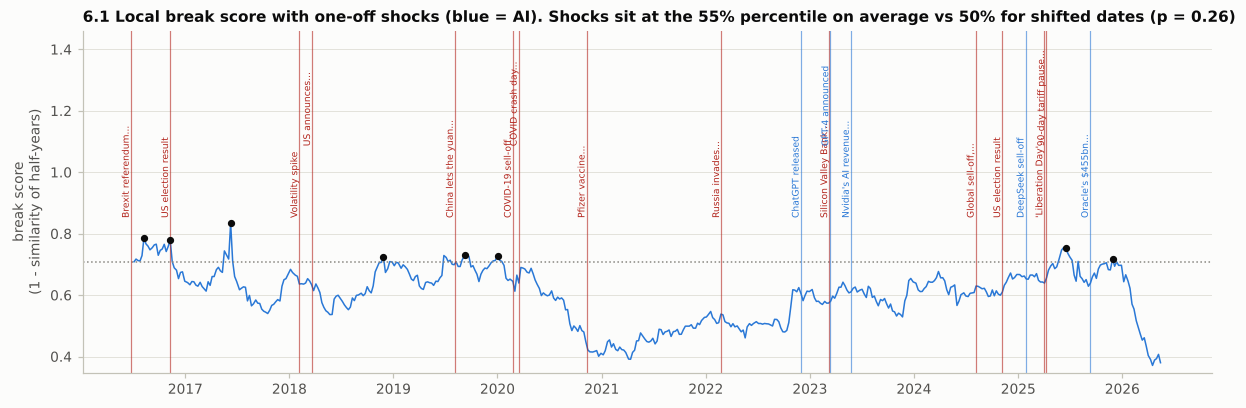

,break percentile,event
2016-11-09,0.996,US election result (Trump)
2018-02-05,0.596,"Volatility spike ('Volmageddon'), Dow -1,175"
2018-03-22,0.590,US announces tariffs on Chinese imports (Secti...
2019-08-05,0.875,China lets the yuan fall below 7 per dollar; w...
2020-02-24,0.654,COVID-19 sell-off begins (outbreak in Italy)
2020-03-16,0.608,COVID crash day after the Fed's Sunday emergen...
2020-11-09,0.066,Pfizer vaccine efficacy result
2022-02-24,0.249,Russia invades Ukraine
2022-11-30,0.437,ChatGPT released
2023-03-10,0.322,Silicon Valley Bank collapse


In [14]:
def shock_break_test(series, shock_days, n=N_SHIFTS):
    pct = series.rank(pct=True).to_numpy()
    grid_pos = np.array([POS[d] for d in series.index])
    shock_pos = np.array([POS[d] for d in shock_days])
    usable = (shock_pos >= grid_pos[0]) & (shock_pos <= grid_pos[-1])
    shock_pos = shock_pos[usable]

    def mean_pct(positions):
        idx = np.abs(grid_pos[None, :] - positions[:, None]).argmin(axis=1)
        return pct[idx].mean()

    observed = mean_pct(shock_pos)
    span = grid_pos[-1] - grid_pos[0]
    null = np.array([mean_pct(grid_pos[0] + (shock_pos - grid_pos[0] + k) % span)
                     for k in rng.integers(MIN_SHIFT, span - MIN_SHIFT, size=n)])
    per_shock = {d.date(): round(float(pct[np.abs(grid_pos - POS[d]).argmin()]), 3)
                 for d, ok in zip(shock_days, usable) if ok}
    return observed, null, float((null >= observed).mean()), per_shock


shock_days_list = list(events.loc[events["event_type"] == "SHOCK", "day"])
obs_b, null_b, p_b, per_shock = shock_break_test(breaks, shock_days_list)
KEY["h1_breaks"] = {"mean_break_percentile_at_shocks": round(obs_b, 3), "null_mean": round(null_b.mean(), 3), "p": p_b,
                    "n_shocks_tested": len(per_shock)}
print(json.dumps(KEY["h1_breaks"], indent=1))

fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(breaks.index, breaks, color="#2a78d6", lw=1)
ax.axhline(breaks.quantile(0.9), color=MUTED, ls=":", lw=1)
for d in peaks:
    ax.scatter([d], [breaks.loc[d]], color=INK, s=14, zorder=4)
ymax = breaks.max()
last_day = None
level = 0
for _, r in events[events["event_type"] == "SHOCK"].drop_duplicates("day").iterrows():
    color = "#2a78d6" if r["category"].startswith("ai") else HIGHLIGHT
    ax.axvline(r["day"], color=color, lw=0.8, alpha=0.6)
    # Shocks closer than ~2 months alternate between two label heights so the labels don't overlap.
    level = 1 - level if last_day is not None and (r["day"] - last_day).days < 60 else 0
    last_day = r["day"]
    ax.text(r["day"], ymax * (1.02 + 0.28 * level), short_label(r["name"], 20), rotation=90, fontsize=6,
            va="bottom", ha="right", color=color)
ax.set_ylabel("break score\n(1 - similarity of half-years)")
ax.set_ylim(top=ymax * 1.75)
year_axis(ax)
ax.grid(axis="y")
ax.set_title(f"6.1 Local break score with one-off shocks (blue = AI). Shocks sit at the {obs_b:.0%} percentile on "
             f"average vs {null_b.mean():.0%} for shifted dates (p = {p_b:.2f})")
save(fig, "6_1_local_breaks_and_shocks")
plt.show()
shock_only = events[events["event_type"] == "SHOCK"].drop_duplicates("day")
shock_names = pd.Series(shock_only["name"].to_numpy(), index=shock_only["day"].dt.date)
pd.Series(per_shock, name="break percentile").to_frame().assign(event=[shock_names[d] for d in per_shock])

**The monthly placebo table from the final notebook.** Its top-10% dates, with shocks within ±63 trading days
(its windows are a full year on each side, so a wider net is needed).

In [15]:
placebo_path = Path("outputs/final/placebo_break_test.csv")
if placebo_path.exists():
    placebo = pd.read_csv(placebo_path, index_col=0, parse_dates=True)
    rows = []
    for col in ["rule_turnover", "tech_change_minus_control"]:
        for d in placebo[col].nlargest(int(np.ceil(0.1 * len(placebo)))).index:
            p = POS[to_trading_day([d])[0]]
            near = events[(events["event_type"] == "SHOCK") & ((events["pos"] - p).abs() <= 63)]
            rows.append({"measure": col, "date": d.date(), "value": round(placebo.loc[d, col], 3),
                         "shocks within ±63 days": "; ".join(near["name"]) or "-"})
    placebo_events = pd.DataFrame(rows)
    placebo_events.to_csv(OUT_DIR / "placebo_top_dates_with_events.csv", index=False)
    display(placebo_events)

,measure,date,value,shocks within ±63 days
0,rule_turnover,2017-05-01,0.991,-
1,rule_turnover,2017-04-03,0.989,-
2,rule_turnover,2025-11-03,0.977,Oracle's $455bn cloud backlog
3,rule_turnover,2025-10-01,0.977,Oracle's $455bn cloud backlog
4,rule_turnover,2025-09-02,0.975,Oracle's $455bn cloud backlog
5,rule_turnover,2017-06-01,0.974,-
6,rule_turnover,2025-08-01,0.972,Oracle's $455bn cloud backlog
7,rule_turnover,2017-03-01,0.971,-
8,rule_turnover,2025-07-01,0.971,'Liberation Day' tariffs announced (2 Apr afte...
9,rule_turnover,2025-06-02,0.960,'Liberation Day' tariffs announced (2 Apr afte...


## 7. Do breaks last? Recovery curves (H2)

For each one-off shock, take the half-year **before** it as the "normal" structure. Then compare it with
half-year windows starting 0, 21, 42, ... 504 trading days **after** it (up to two years). Similarity = the
correlation of the 780 pair lifts, as in Section 6.

Similarity falls with distance even without any event, because the market drifts. So every curve is compared with
the **normal drift**: the same calculation started at every month of the sample. The plotted value is the gap to
normal drift in standard deviations: 0 = an ordinary month, −1 = one standard deviation less similar than usual.

**Reading a curve.** A dip at the start that comes back to 0 = **temporary** break. A dip that stays = **lasting**
change. No dip = **no break**. Rule used (written down before running):

* no break: the lowest value in the first quarter (offsets 0–63) is above −1;
* temporary: early dip below −1, and the mean over the second year (offsets 252–504) is above −0.5;
* lasting: early dip below −1, and the second-year mean is −1 or lower;
* partial: anything in between; too recent: less than one year of data after the event; too early: the event
  is less than half a year after the first basket, so there is no "before" window.

In [16]:
def recovery_curves(basket, event_days_, pairs=(PAIR_I, PAIR_J)):
    lv = LiftCache(basket, pairs)
    n = len(basket)

    def curve(p):
        if p - SPAN < 0:
            return [np.nan] * len(H2_OFFSETS)
        pre = lv(p - SPAN)
        return [similarity(pre, lv(p + k)) if p + k + SPAN <= n else np.nan for k in H2_OFFSETS]

    normal_starts = range(SPAN, n - SPAN, 21)
    normal = pd.DataFrame([curve(p) for p in normal_starts], columns=H2_OFFSETS)
    mu, sd = normal.mean(), normal.std()
    ev = {d: (np.array(curve(POS[d])) - mu.to_numpy()) / sd.to_numpy() for d in event_days_}
    return pd.DataFrame(ev, index=H2_OFFSETS).T, mu, sd


def classify(z):
    early_vals = z[[k for k in H2_OFFSETS if k <= 63]].to_numpy()
    if not np.isfinite(early_vals).any():
        return "too early (no half-year before)", np.nan, np.nan
    early = np.nanmin(early_vals)
    late_cols = [k for k in H2_OFFSETS if 252 <= k <= 504]
    late_vals = z[late_cols].to_numpy()
    if np.isfinite(late_vals).sum() < 4:
        return "too recent", early, np.nan
    late = np.nanmean(late_vals)
    if early > -1:
        return "no break", early, late
    if late > -0.5:
        return "temporary", early, late
    if late <= -1:
        return "lasting", early, late
    return "partial", early, late


shock_rows = events[events["event_type"] == "SHOCK"].drop_duplicates("day")
curves, normal_mu, normal_sd = recovery_curves(items, list(shock_rows["day"]))
ai_pairs = tuple(np.array(x) for x in zip(*[(i, j) for i, j in zip(PAIR_I, PAIR_J)
                                             if GROUP_OF[TICKERS[i]] == "AI enablers" or GROUP_OF[TICKERS[j]] == "AI enablers"]))
curves_ai, _, _ = recovery_curves(items, list(shock_rows["day"]), pairs=ai_pairs)

h2 = []
for (_, r), (d, z) in zip(shock_rows.iterrows(), curves.iterrows()):
    label, early, late = classify(z)
    label_ai, early_ai, late_ai = classify(curves_ai.loc[d])
    h2.append({"date": d.date(), "event": r["name"], "category": r["category"],
               "result (all pairs)": label, "early dip": early, "second-year mean": late,
               "result (pairs with an AI stock)": label_ai, "early dip (AI)": early_ai, "second-year mean (AI)": late_ai})
h2 = pd.DataFrame(h2)
h2.to_csv(OUT_DIR / "h2_recovery_classification.csv", index=False)
KEY["h2_counts_all_pairs"] = h2["result (all pairs)"].value_counts().to_dict()
KEY["h2_counts_ai_pairs"] = h2["result (pairs with an AI stock)"].value_counts().to_dict()
KEY["h2_by_event"] = {f"{r.date} {r.event}": [r._4, r._7] for r in h2.itertuples()}
print("All pairs:", KEY["h2_counts_all_pairs"])
print("Pairs with an AI stock:", KEY["h2_counts_ai_pairs"])
h2.round(2)

All pairs: {'no break': 12, 'lasting': 3, 'too recent': 3, 'too early (no half-year before)': 1}
Pairs with an AI stock: {'no break': 10, 'temporary': 4, 'too recent': 3, 'too early (no half-year before)': 1, 'lasting': 1}


,date,event,category,result (all pairs),early dip,second-year mean,result (pairs with an AI stock),early dip (AI),second-year mean (AI)
0,2016-06-24,Brexit referendum result,geopolitical,too early (no half-year before),NaN,NaN,too early (no half-year before),NaN,NaN
1,2016-11-09,US election result (Trump),policy,lasting,-1.98,-1.98,no break,-0.71,-1.41
2,2018-02-05,"Volatility spike ('Volmageddon'), Dow -1,175",market,no break,-0.93,-0.27,temporary,-2.10,-0.46
3,2018-03-22,US announces tariffs on Chinese imports (Secti...,policy,no break,-0.34,0.21,temporary,-1.35,0.17
4,2019-08-05,China lets the yuan fall below 7 per dollar; w...,policy,lasting,-1.21,-1.03,lasting,-1.50,-1.27
5,2020-02-24,COVID-19 sell-off begins (outbreak in Italy),health,no break,-0.78,0.69,temporary,-2.20,0.03
6,2020-03-16,COVID crash day after the Fed's Sunday emergen...,health,no break,-0.93,0.60,temporary,-1.83,0.43
7,2020-11-09,Pfizer vaccine efficacy result,health,no break,1.58,1.02,no break,-0.59,-0.32
8,2022-02-24,Russia invades Ukraine,geopolitical,no break,0.64,0.33,no break,0.34,0.70
9,2022-11-30,ChatGPT released,ai_launch,no break,-0.35,0.30,no break,0.14,1.12


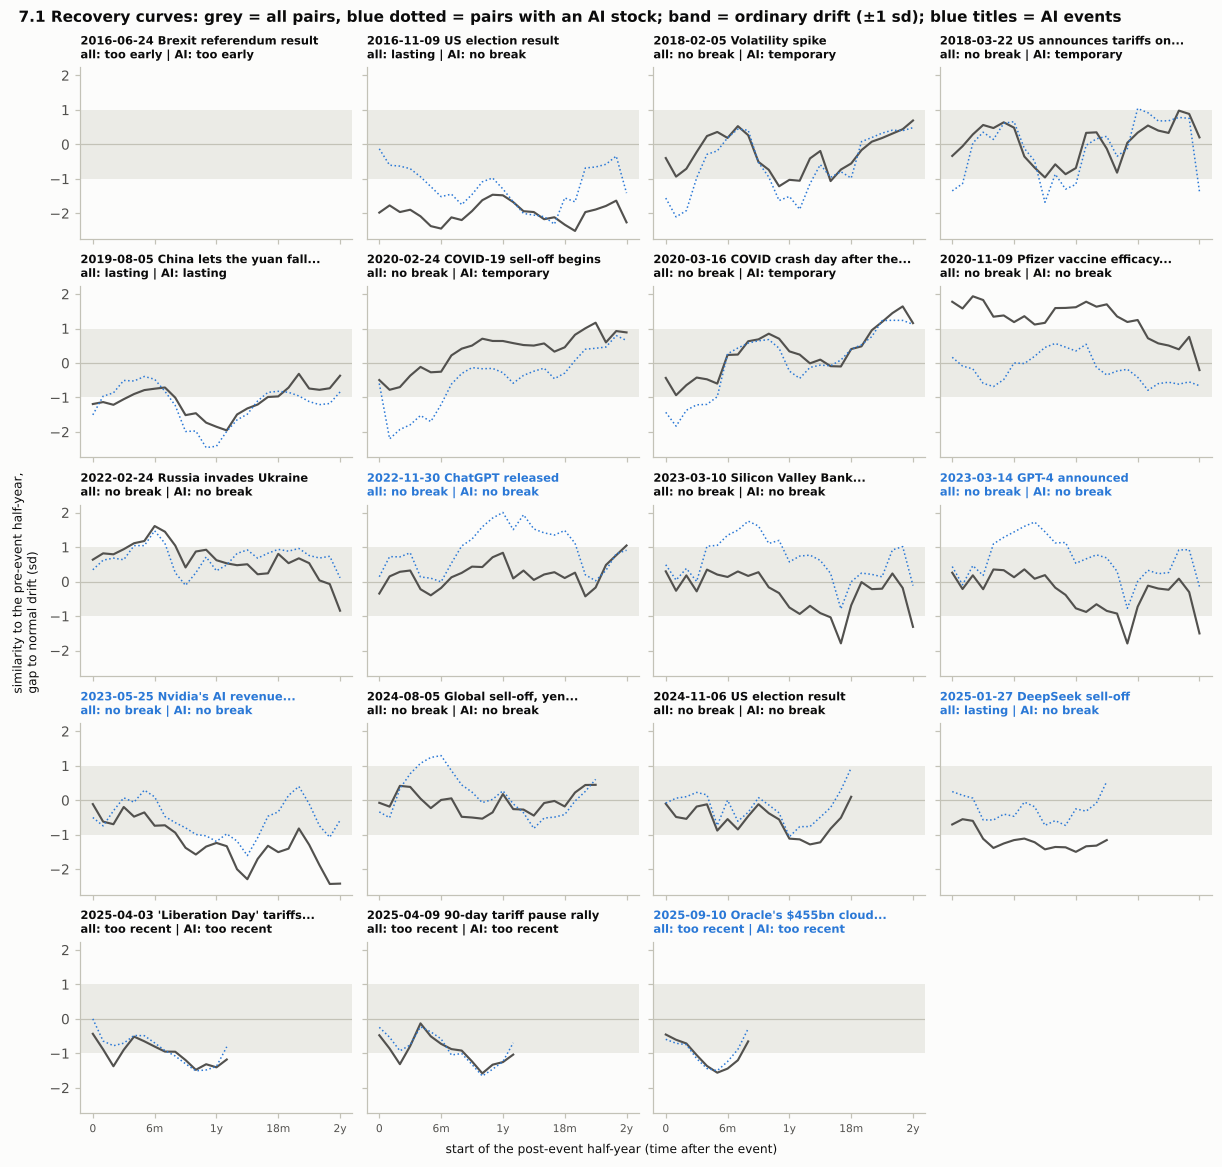

In [17]:
n = len(curves)
ncol = 4
fig, axes = plt.subplots(int(np.ceil(n / ncol)), ncol, figsize=(11, 2.1 * np.ceil(n / ncol)), sharex=True, sharey=True,
                         layout="constrained")
for ax, (d, z), (_, r) in zip(axes.flat, curves.iterrows(), h2.iterrows()):
    ax.axhspan(-1, 1, color=GRID, alpha=0.6, lw=0)
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.plot(H2_OFFSETS, z.to_numpy(), color=INK_SOFT, lw=1.4)
    ax.plot(H2_OFFSETS, curves_ai.loc[d].to_numpy(), color="#2a78d6", lw=1, ls=":")
    ai_event = r["category"].startswith("ai")
    ax.set_title(f"{d.date()} {short_label(r['event'], 26)}\nall: {r['result (all pairs)'].split(' (')[0]} | "
                 f"AI: {r['result (pairs with an AI stock)'].split(' (')[0]}", fontsize=7.5,
                 color="#2a78d6" if ai_event else INK)
    ax.set_xticks([0, 126, 252, 378, 504], ["0", "6m", "1y", "18m", "2y"], fontsize=7)
for ax in list(axes.flat)[n:]:
    ax.axis("off")
fig.supxlabel("start of the post-event half-year (time after the event)", fontsize=8)
fig.supylabel("similarity to the pre-event half-year,\ngap to normal drift (sd)", fontsize=8)
fig.suptitle("7.1 Recovery curves: grey = all pairs, blue dotted = pairs with an AI stock; band = ordinary drift (±1 sd); blue titles = AI events",
             x=0.01, ha="left", fontweight="bold", fontsize=10)
save(fig, "7_1_recovery_curves")
plt.show()

## 8. Robustness: do the answers change with the settings?

The main results again under a stricter major move (z ≥ 1.5) and under raw returns (market not removed). The raw
setting is expected to look different: the final notebook showed that without removing the market, rules mostly
rediscover the market.

In [18]:
def core_results(mode, z_k):
    its, z = build_items(mode, z_k)
    an = anomaly_scores(z)
    top = np.array([POS[d] for d in an.nlargest(n_top).index])
    obs, null, p = shift_test(top, [macro_mask, shock_mask], n=300)
    br = local_break_series(its)
    ob, nb, pb, _ = shock_break_test(br, shock_days_list, n=300)
    cv, _, _ = recovery_curves(its, list(shock_rows["day"]))
    labels = [classify(z_)[0] for _, z_ in cv.iterrows()]
    return {"unusual days matched": round(obs, 2), "shifted calendars": round(null.mean(), 2), "p (unusual days)": round(p, 3),
            "shock break percentile": round(ob, 2), "shifted shocks": round(nb.mean(), 2), "p (breaks)": round(pb, 3),
            "H2 temporary": labels.count("temporary"), "H2 lasting": labels.count("lasting"),
            "H2 no break": labels.count("no break"), "H2 partial": labels.count("partial")}


robust = pd.DataFrame({
    "main: residual, z = 1.0": core_results("residual", 1.0),
    "residual, z = 1.5": core_results("residual", 1.5),
    "raw returns, z = 1.0": core_results("raw", 1.0),
}).T
robust.to_csv(OUT_DIR / "robustness.csv")
KEY["robustness"] = robust.to_dict(orient="index")
robust

,unusual days matched,shifted calendars,p (unusual days),shock break percentile,shifted shocks,p (breaks),H2 temporary,H2 lasting,H2 no break,H2 partial
"main: residual, z = 1.0",0.41,0.14,0.0,0.55,0.5,0.263,0.0,3.0,12.0,0.0
"residual, z = 1.5",0.41,0.14,0.0,0.64,0.5,0.050,2.0,1.0,12.0,0.0
"raw returns, z = 1.0",0.44,0.14,0.0,0.51,0.5,0.403,2.0,0.0,10.0,3.0


## 9. Key numbers

Every number used in the report comes from this file.

In [19]:
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else round(float(o), 4)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    if isinstance(o, pd.Timestamp):
        return str(o.date())
    return o


with open(OUT_DIR / "key_numbers_events.json", "w") as f:
    json.dump(to_jsonable(KEY), f, indent=1)
print(json.dumps(to_jsonable({k: KEY[k] for k in ["h1c", "h1_breaks", "h2_counts_all_pairs", "h2_counts_ai_pairs"]}), indent=1))

{
 "h1c": {
  "n_top_days": 27,
  "share_matched_macro_or_shock": 0.407,
  "null_mean": 0.139,
  "p": 0.001,
  "share_matched_macro": 0.111,
  "null_mean_macro": 0.125,
  "p_macro": 0.695,
  "share_matched_shock": 0.37,
  "null_mean_shock": 0.019,
  "p_shock": 0.0
 },
 "h1_breaks": {
  "mean_break_percentile_at_shocks": 0.547,
  "null_mean": 0.5,
  "p": 0.261,
  "n_shocks_tested": 18
 },
 "h2_counts_all_pairs": {
  "no break": 12,
  "lasting": 3,
  "too recent": 3,
  "too early (no half-year before)": 1
 },
 "h2_counts_ai_pairs": {
  "no break": 10,
  "temporary": 4,
  "too recent": 3,
  "too early (no half-year before)": 1,
  "lasting": 1
 }
}
